# Chapter 2 — 패킷 캡처와 분석: tcpdump · Wireshark · tshark (실습)

## 실습 목표
1. tcpdump 로 캡처 파일을 훑고, BPF 캡처 필터로 좁히고, 일부를 새 파일로 저장했다가 다시 읽는다.
2. Wireshark 의 세 영역(패킷 목록·상세·바이트)에 대응하는 tshark 출력으로 한 패킷을 끝까지 해석한다.
3. 표시 필터·Follow Stream·통계로 캡처 파일 속 의심 행위 세 가지(스캔·평문 로그인·비컨)를 찾는다.
4. tshark 필드 추출 결과를 pandas 로 받아 탐지 근거를 표와 그래프로 정리한다.

## 환경
- Google Colab: 설치 셀이 `tcpdump`·`tshark` 를 설치한다. root 로 동작하므로 실시간 캡처(Step 2)도 된다.
- 로컬 Linux·macOS: `tcpdump` 와 Wireshark(tshark 포함)를 설치한다. Windows 는 WSL(Ubuntu) 에서 실행한다.
- 본문 2.1~2.4절의 명령과 출력이 이 노트북과 같다. 시각은 UTC 로 맞춘다.

---
## Step 0. 환경 설정

`tcpdump`·`tshark`·`capinfos`·`editcap` 이 있는지 확인하고, Colab 처럼 root 권한이 있는 Ubuntu 환경이면 설치한다.

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q scapy pandas matplotlib

In [2]:
import os
import shutil
import subprocess

os.environ["TZ"] = "UTC"   # tcpdump·tshark 가 책과 같은 UTC 시각으로 출력하도록 맞춘다

TOOLS = ["tcpdump", "tshark", "capinfos", "editcap"]
is_root = hasattr(os, "geteuid") and os.geteuid() == 0
if any(shutil.which(t) is None for t in TOOLS) and shutil.which("apt-get") and is_root:
    subprocess.run(
        "DEBIAN_FRONTEND=noninteractive apt-get -qq update && "
        "DEBIAN_FRONTEND=noninteractive apt-get -qq install -y tcpdump tshark > /dev/null",
        shell=True, check=True,
    )

for t in TOOLS:
    print(f"{t:9s} {shutil.which(t) or '없음 — Wireshark·tcpdump 패키지를 설치한다'}")
missing = [t for t in TOOLS if shutil.which(t) is None]
if missing:
    raise RuntimeError('필수 시스템 도구 없음: ' + ', '.join(missing) +
                       '. Ubuntu/Colab: sudo apt-get install tcpdump tshark; '
                       'Windows/macOS: Wireshark CLI 도구를 설치하고 PATH에 추가한다.')
print(subprocess.run(["tshark", "-v"], capture_output=True, text=True, check=True).stdout.splitlines()[0])

tcpdump   /tmp/book-final-packet-tools/root/usr/bin/tcpdump
tshark    /tmp/book-final-packet-tools/root/usr/bin/tshark
capinfos  /tmp/book-final-packet-tools/root/usr/bin/capinfos
editcap   /tmp/book-final-packet-tools/root/usr/bin/editcap
TShark (Wireshark) 3.6.2 (Git v3.6.2 packaged as 3.6.2-2)


In [3]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

---
## Step 1. 실습용 캡처 파일 준비 — office_lan.pcap

사무실 LAN 한 구간을 약 28초간 캡처한 상황을 재현한 파일을 만든다. 모든 수강생이 같은 결과를 얻도록 파일을 코드로 생성한다.
패킷을 코드로 만드는 방법(Scapy)은 ch03 에서 배우므로, 지금은 셀을 실행해 파일만 준비한다.

In [4]:
# 실습용 캡처 파일 생성 — 사무실 LAN 한 구간을 약 30초간 캡처했다고 가정
from pathlib import Path
from scapy.all import Ether, ARP, IP, ICMP, TCP, UDP, DNS, DNSQR, DNSRR, Raw, wrpcap

PCAP_PATH = Path.cwd() / "office_lan.pcap"

GW_MAC, PC_MAC, SRV_MAC, SCAN_MAC = "00:1a:2b:00:00:01", "3c:52:82:4a:10:23", "00:50:56:aa:00:05", "08:00:27:5e:77:77"
GW, PC, SRV, SCAN = "192.168.10.1", "192.168.10.23", "192.168.10.5", "192.168.10.77"
WEB, C2 = "198.51.100.20", "203.0.113.66"          # 문서용 예약 대역(RFC 5737)
T0_US = 1773306842_000000                           # 2026-03-12 09:14:02 UTC (마이크로초)

from decimal import Decimal
pkts, t_us = [], T0_US
def add(p, dt=0.001):
    global t_us
    t_us += round(dt * 1_000_000)
    p.time = Decimal(t_us) / Decimal(1_000_000)
    pkts.append(p)

def tcp_session(cmac, smac, cip, sip, cport, sport, request, response, dt_first, isn_c, isn_s, ttl_s):
    """3-way handshake → 요청 → 응답 → 4-way 종료까지 한 TCP 세션."""
    E_c = Ether(src=cmac, dst=smac); E_s = Ether(src=smac, dst=cmac)
    c, s = isn_c, isn_s
    add(E_c/IP(src=cip, dst=sip, ttl=64, id=0x4a10)/TCP(sport=cport, dport=sport, flags="S", seq=c, window=64240,
        options=[("MSS", 1460), ("SAckOK", b""), ("Timestamp", (0, 0)), ("NOP", None), ("WScale", 7)]), dt_first)
    add(E_s/IP(src=sip, dst=cip, ttl=ttl_s)/TCP(sport=sport, dport=cport, flags="SA", seq=s, ack=c+1, window=65160,
        options=[("MSS", 1460), ("SAckOK", b""), ("NOP", None), ("WScale", 7)]), 0.0312)
    c += 1; s += 1
    add(E_c/IP(src=cip, dst=sip, ttl=64)/TCP(sport=cport, dport=sport, flags="A", seq=c, ack=s, window=502), 0.0004)
    add(E_c/IP(src=cip, dst=sip, ttl=64)/TCP(sport=cport, dport=sport, flags="PA", seq=c, ack=s, window=502)/Raw(request), 0.0003)
    c += len(request)
    add(E_s/IP(src=sip, dst=cip, ttl=ttl_s)/TCP(sport=sport, dport=cport, flags="A", seq=s, ack=c, window=509), 0.0298)
    add(E_s/IP(src=sip, dst=cip, ttl=ttl_s)/TCP(sport=sport, dport=cport, flags="PA", seq=s, ack=c, window=509)/Raw(response), 0.0021)
    s += len(response)
    add(E_c/IP(src=cip, dst=sip, ttl=64)/TCP(sport=cport, dport=sport, flags="A", seq=c, ack=s, window=501), 0.0002)
    add(E_c/IP(src=cip, dst=sip, ttl=64)/TCP(sport=cport, dport=sport, flags="FA", seq=c, ack=s, window=501), 0.0850)
    add(E_s/IP(src=sip, dst=cip, ttl=ttl_s)/TCP(sport=sport, dport=cport, flags="FA", seq=s, ack=c+1, window=509), 0.0301)
    add(E_c/IP(src=cip, dst=sip, ttl=64)/TCP(sport=cport, dport=sport, flags="A", seq=c+1, ack=s+1, window=501), 0.0003)

# 1) ARP — PC 가 게이트웨이 MAC 을 묻는다
add(Ether(src=PC_MAC, dst="ff:ff:ff:ff:ff:ff")/ARP(op=1, hwsrc=PC_MAC, psrc=PC, pdst=GW), 0.0)
add(Ether(src=GW_MAC, dst=PC_MAC)/ARP(op=2, hwsrc=GW_MAC, psrc=GW, hwdst=PC_MAC, pdst=PC), 0.0012)

# 2) ICMP — 게이트웨이 ping 2회
for i in (1, 2):
    add(Ether(src=PC_MAC, dst=GW_MAC)/IP(src=PC, dst=GW, ttl=64)/ICMP(type=8, id=0x1f2e, seq=i)/Raw(b"abcdefghijklmnopqrstuvwabcdefghi"), 0.4 if i == 1 else 0.9990)
    add(Ether(src=GW_MAC, dst=PC_MAC)/IP(src=GW, dst=PC, ttl=64)/ICMP(type=0, id=0x1f2e, seq=i)/Raw(b"abcdefghijklmnopqrstuvwabcdefghi"), 0.0009)

# 3) DNS — 정상 웹사이트 조회
add(Ether(src=PC_MAC, dst=GW_MAC)/IP(src=PC, dst=GW, ttl=64)/UDP(sport=51514, dport=53)/DNS(id=0x7c21, rd=1, qd=DNSQR(qname="www.example.com")), 1.2)
add(Ether(src=GW_MAC, dst=PC_MAC)/IP(src=GW, dst=PC, ttl=64)/UDP(sport=53, dport=51514)/DNS(id=0x7c21, qr=1, rd=1, ra=1, qd=DNSQR(qname="www.example.com"),
    an=DNSRR(rrname="www.example.com", ttl=300, rdata=WEB)), 0.0184)

# 4) HTTP — 브라우저로 로그인 페이지 조회 (평문)
req1 = (b"GET /login HTTP/1.1\r\nHost: www.example.com\r\n"
        b"User-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36\r\n"
        b"Accept: text/html\r\nConnection: close\r\n\r\n")
body1 = b"<html><head><title>Login</title></head><body><form method=post action=/login>ID <input name=id> PW <input name=pw type=password></form></body></html>"
res1 = b"HTTP/1.1 200 OK\r\nContent-Type: text/html\r\nContent-Length: " + str(len(body1)).encode() + b"\r\nServer: nginx\r\nConnection: close\r\n\r\n" + body1
tcp_session(PC_MAC, GW_MAC, PC, WEB, 50412, 80, req1, res1, 0.0021, 2811470201, 1937361022, 53)

# 5) HTTP POST — 평문 로그인 (자격증명이 그대로 보인다)
req2 = (b"POST /login HTTP/1.1\r\nHost: www.example.com\r\n"
        b"User-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36\r\n"
        b"Content-Type: application/x-www-form-urlencoded\r\nContent-Length: 24\r\nConnection: close\r\n\r\n"
        b"id=kim.analyst&pw=Spring")
res2 = b"HTTP/1.1 302 Found\r\nLocation: /home\r\nContent-Length: 0\r\nServer: nginx\r\nConnection: close\r\n\r\n"
tcp_session(PC_MAC, GW_MAC, PC, WEB, 50418, 80, req2, res2, 3.4, 3024417790, 4102299311, 53)

# 6) 의심 DNS — 긴 무작위 하위 도메인 조회 3회 (DNS 터널링·DGA 모양)
for i, label in enumerate(["q7zk2m9x4tr1bv8c", "p0w3n6yd5ha2lsu7", "t8re1ck4vz9gm3qx"]):
    qn = f"{label}.cdn-update-check.net"
    add(Ether(src=PC_MAC, dst=GW_MAC)/IP(src=PC, dst=GW, ttl=64)/UDP(sport=53112 + i, dport=53)/DNS(id=0x3a00 + i, rd=1, qd=DNSQR(qname=qn, qtype="TXT")), 6.0 if i == 0 else 5.0)
    add(Ether(src=GW_MAC, dst=PC_MAC)/IP(src=GW, dst=PC, ttl=64)/UDP(sport=53, dport=53112 + i)/DNS(id=0x3a00 + i, qr=1, rd=1, ra=1, qd=DNSQR(qname=qn, qtype="TXT"),
        an=DNSRR(rrname=qn, type="TXT", ttl=0, rdata="ok")), 0.0412)

# 7) HTTP — 스크립트(curl)가 수상한 서버에 비컨 전송
req3 = (b"POST /api/v2/beacon HTTP/1.1\r\nHost: cdn-update-check.net\r\nUser-Agent: curl/8.5.0\r\n"
        b"Content-Type: application/json\r\nContent-Length: 38\r\n\r\n"
        b'{"host":"PC-0223","uid":"kim.analyst"}')
res3 = b"HTTP/1.1 200 OK\r\nContent-Type: application/json\r\nContent-Length: 15\r\n\r\n{\"task\":\"none\"}"
tcp_session(PC_MAC, GW_MAC, PC, C2, 50433, 80, req3, res3, 0.9, 1188021554, 2257103349, 47)

# 8) SYN 스캔 — 내부 호스트 .77 이 서버 .5 의 포트를 훑는다
E_a, E_v = Ether(src=SCAN_MAC, dst=SRV_MAC), Ether(src=SRV_MAC, dst=SCAN_MAC)
first = True
for port in [21, 22, 23, 25, 80, 110, 139, 443, 445, 3306, 3389, 8080]:
    add(E_a/IP(src=SCAN, dst=SRV, ttl=64, id=54321)/TCP(sport=61234, dport=port, flags="S", seq=4100000000, window=1024,
        options=[("MSS", 1460)]), 4.0 if first else 0.0008)
    first = False
    if port in (22, 80, 443):
        add(E_v/IP(src=SRV, dst=SCAN, ttl=64)/TCP(sport=port, dport=61234, flags="SA", seq=770000000 + port, ack=4100000001, window=65160,
            options=[("MSS", 1460)]), 0.0003)
        add(E_a/IP(src=SCAN, dst=SRV, ttl=64)/TCP(sport=61234, dport=port, flags="R", seq=4100000001, window=0), 0.0001)
    else:
        add(E_v/IP(src=SRV, dst=SCAN, ttl=64)/TCP(sport=port, dport=61234, flags="RA", seq=0, ack=4100000001, window=0), 0.0002)

wrpcap(str(PCAP_PATH), pkts)
print(f"{PCAP_PATH.name}: {len(pkts)} packets")

office_lan.pcap: 71 packets


In [5]:
!capinfos office_lan.pcap

File name:           office_lan.pcap
File type:           Wireshark/tcpdump/... - pcap
File encapsulation:  Ethernet
File timestamp precision:  microseconds (6)
Packet size limit:   file hdr: 65535 bytes
Number of packets:   71
File size:           6778 bytes
Data size:           5618 bytes
Capture duration:    27.596100 seconds
First packet time:   2026-03-12 09:14:02.000000
Last packet time:    2026-03-12 09:14:29.596100
Data byte rate:      203 bytes/s
Data bit rate:       1628 bits/s
Average packet size: 79.13 bytes
Average packet rate: 2 packets/s
SHA256:              a9ed61a8c2a4301ae65e666016ec3a1e4e9cba34dd7bbcb14a861f34a043fa5b
RIPEMD160:           7bd791491678e0dea9f4f58d774acae05e636732
SHA1:                326858d3b5bc980c50310db5ccca5b954e2ef23b
Strict time order:   True
Number of interfaces in file: 1
Interface #0 info:
                     Encapsulation = Ethernet (1 - ether)
                     Capture length = 65535
                     Time precision = microseconds (

---
## Step 2. (선택) 실시간 캡처 — Colab 에서만

Colab 은 root 로 동작하므로 `tcpdump -i any` 로 실제 트래픽을 잡을 수 있다. 캡처를 백그라운드로 띄우고 `curl` 로 웹 요청을 보낸 뒤, 저장된 파일을 읽는다.
권한이 없는 환경에서는 건너뛴다.

In [6]:
import time

if is_root and shutil.which("tcpdump") and shutil.which("curl"):
    cap = subprocess.Popen(
        ["tcpdump", "-i", "any", "-n", "-c", "30", "-w", "live.pcap", "tcp port 80 or udp port 53"],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )
    time.sleep(2)                                   # 캡처가 시작될 시간
    subprocess.run(["curl", "-s", "-o", "/dev/null", "http://example.com/"])
    try:
        cap.wait(timeout=10)
    except subprocess.TimeoutExpired:
        cap.terminate()                             # 방금 띄운 캡처 프로세스만 종료
        cap.wait()
    r = subprocess.run(["tcpdump", "-r", "live.pcap", "-n", "-c", "12"], capture_output=True, text=True)
    print(r.stdout)
else:
    print("실시간 캡처 권한이 없어 건너뛴다. 이후 단계는 office_lan.pcap 으로 진행한다.")

실시간 캡처 권한이 없어 건너뛴다. 이후 단계는 office_lan.pcap 으로 진행한다.


---
## Step 3. tcpdump 출력 읽기

본문 2.2.3~2.2.4절. `-n` 은 주소·포트를 이름으로 바꾸지 않고, `-c` 는 개수를 제한한다.

In [7]:
!tcpdump -r office_lan.pcap -n -c 10

reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:02.000000 ARP, Request who-has 192.168.10.1 tell 192.168.10.23, length 28
09:14:02.001200 ARP, Reply 192.168.10.1 is-at 00:1a:2b:00:00:01, length 28
09:14:02.401200 IP 192.168.10.23 > 192.168.10.1: ICMP echo request, id 7982, seq 1, length 40
09:14:02.402100 IP 192.168.10.1 > 192.168.10.23: ICMP echo reply, id 7982, seq 1, length 40
09:14:03.401100 IP 192.168.10.23 > 192.168.10.1: ICMP echo request, id 7982, seq 2, length 40
09:14:03.402000 IP 192.168.10.1 > 192.168.10.23: ICMP echo reply, id 7982, seq 2, length 40
09:14:04.602000 IP 192.168.10.23.51514 > 192.168.10.1.53: 31777+ A? www.example.com. (33)
09:14:04.620400 IP 192.168.10.1.53 > 192.168.10.23.51514: 31777 1/0/0 A 198.51.100.20 (64)
09:14:04.622500 IP 192.168.10.23.50412 > 198.51.100.20.80: Flags [S], seq 2811470201, win 64240, options [mss 1460,sackOK,TS val 0 ecr 0,nop,wscale 7], length 0
09:14:04.653700 IP 198.51.100.20.80 > 192.168

**관찰 포인트**
- ARP 요청은 `who-has`, 응답은 `is-at` 으로 나온다.
- TCP 줄의 `Flags [S]` → `[S.]` → `[.]` 가 3-way handshake 다. `.` 은 ACK 를 뜻한다.
- DNS 줄의 `31777+ A? www.example.com.` 은 트랜잭션 ID·재귀 요청·질의 유형·이름이다.

In [8]:
# 링크 계층(MAC)과 IP 헤더 세부
!tcpdump -r office_lan.pcap -n -e -c 2
!tcpdump -r office_lan.pcap -n -v -c 1 'icmp'

reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:02.000000 3c:52:82:4a:10:23 > ff:ff:ff:ff:ff:ff, ethertype ARP (0x0806), length 42: Request who-has 192.168.10.1 tell 192.168.10.23, length 28
09:14:02.001200 00:1a:2b:00:00:01 > 3c:52:82:4a:10:23, ethertype ARP (0x0806), length 42: Reply 192.168.10.1 is-at 00:1a:2b:00:00:01, length 28


reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:02.401200 IP (tos 0x0, ttl 64, id 1, offset 0, flags [none], proto ICMP (1), length 60)
    192.168.10.23 > 192.168.10.1: ICMP echo request, id 7982, seq 1, length 40


**과제 1.** DNS 질의 패킷 1개를 16진수+ASCII 로 출력한다.  
힌트: `-X` 옵션과 `'udp port 53'` 필터, `-c 1`

In [9]:
# DNS 질의 패킷 1개를 16진수+ASCII 로 출력한다.
!tcpdump -r office_lan.pcap -n -X -c 1 'udp port 53'

reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:04.602000 IP 192.168.10.23.51514 > 192.168.10.1.53: 31777+ A? www.example.com. (33)
	0x0000:  4500 003d 0001 0000 4011 e546 c0a8 0a17  E..=....@..F....
	0x0010:  c0a8 0a01 c93a 0035 0029 da45 7c21 0100  .....:.5.).E|!..
	0x0020:  0001 0000 0000 0000 0377 7777 0765 7861  .........www.exa
	0x0030:  6d70 6c65 0363 6f6d 0000 0100 01         mple.com.....


**과제 2.** PSH 가 켜진(데이터를 담은) HTTP 패킷 1개의 페이로드를 ASCII 로 출력한다.  
힌트: `-A` 옵션, `tcp[tcpflags] & tcp-push != 0`

In [10]:
# PSH 가 켜진(데이터를 담은) HTTP 패킷 1개의 페이로드를 ASCII 로 출력한다.
!tcpdump -r office_lan.pcap -n -A -c 1 'tcp port 80 and tcp[tcpflags] & tcp-push != 0'

reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:04.654400 IP 192.168.10.23.50412 > 198.51.100.20.80: Flags [P.], seq 2811470202:2811470407, ack 1937361023, win 502, length 205: HTTP: GET /login HTTP/1.1
E.......@.....
..3d....P...zsy..P.......GET /login HTTP/1.1
Host: www.example.com
User-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36
Accept: text/html
Connection: close




---
## Step 4. BPF 캡처 필터

본문 2.2.5절. 필터는 작은따옴표로 감싼다. 같은 문법이 실시간 캡처(`-i`)에도 그대로 쓰인다.

**과제 3.** SYN 플래그만 켜진 패킷을 모두 출력한다.  
힌트: `tcp[tcpflags] == tcp-syn`

In [11]:
# SYN 플래그만 켜진 패킷을 모두 출력한다.
!tcpdump -r office_lan.pcap -n 'tcp[tcpflags] == tcp-syn'

reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:04.622500 IP 192.168.10.23.50412 > 198.51.100.20.80: Flags [S], seq 2811470201, win 64240, options [mss 1460,sackOK,TS val 0 ecr 0,nop,wscale 7], length 0
09:14:08.201900 IP 192.168.10.23.50418 > 198.51.100.20.80: Flags [S], seq 3024417790, win 64240, options [mss 1460,sackOK,TS val 0 ecr 0,nop,wscale 7], length 0
09:14:25.404900 IP 192.168.10.23.50433 > 203.0.113.66.80: Flags [S], seq 1188021554, win 64240, options [mss 1460,sackOK,TS val 0 ecr 0,nop,wscale 7], length 0
09:14:29.584300 IP 192.168.10.77.61234 > 192.168.10.5.21: Flags [S], seq 4100000000, win 1024, options [mss 1460], length 0
09:14:29.585300 IP 192.168.10.77.61234 > 192.168.10.5.22: Flags [S], seq 4100000000, win 1024, options [mss 1460], length 0
09:14:29.586500 IP 192.168.10.77.61234 > 192.168.10.5.23: Flags [S], seq 4100000000, win 1024, options [mss 1460], length 0
09:14:29.587500 IP 192.168.10.77.61234 > 192.168.10.5.25: Fl

**과제 4.** RST 플래그가 켜진 패킷의 개수를 센다. (stderr 의 'reading from file' 줄은 버린다)  
힌트: `tcp[tcpflags] & tcp-rst != 0` 결과를 `2>/dev/null | wc -l` 로 센다. 기대값 12

In [12]:
# RST 플래그가 켜진 패킷의 개수를 센다. (stderr 의 'reading from file' 줄은 버린다)
!tcpdump -r office_lan.pcap -n 'tcp[tcpflags] & tcp-rst != 0' 2>/dev/null | wc -l

12


In [13]:
# 특정 호스트, 방향·프로토콜 조합
!tcpdump -r office_lan.pcap -n 'udp port 53 and src host 192.168.10.23'
!tcpdump -r office_lan.pcap -n 'arp[6:2] == 2'

reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:04.602000 IP 192.168.10.23.51514 > 192.168.10.1.53: 31777+ A? www.example.com. (33)
09:14:14.381300 IP 192.168.10.23.53112 > 192.168.10.1.53: 14848+ TXT? q7zk2m9x4tr1bv8c.cdn-update-check.net. (55)
09:14:19.422500 IP 192.168.10.23.53113 > 192.168.10.1.53: 14849+ TXT? p0w3n6yd5ha2lsu7.cdn-update-check.net. (55)
09:14:24.463700 IP 192.168.10.23.53114 > 192.168.10.1.53: 14850+ TXT? t8re1ck4vz9gm3qx.cdn-update-check.net. (55)


reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:02.001200 ARP, Reply 192.168.10.1 is-at 00:1a:2b:00:00:01, length 28


In [14]:
# TCP 페이로드가 "POST" 로 시작하는 패킷 — 바이트 위치 비교
!tcpdump -r office_lan.pcap -n -A 'tcp port 80 and (tcp[((tcp[12:1] & 0xf0) >> 2):4] = 0x504f5354)'

reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535
09:14:08.233800 IP 192.168.10.23.50418 > 198.51.100.20.80: Flags [P.], seq 3024417791:3024418071, ack 4102299312, win 502, length 280: HTTP: POST /login HTTP/1.1
E..@....@.....
..3d....P.D......P...=h..POST /login HTTP/1.1
Host: www.example.com
User-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36
Content-Type: application/x-www-form-urlencoded
Content-Length: 24
Connection: close

id=kim.analyst&pw=Spring
09:14:25.436800 IP 192.168.10.23.50433 > 203.0.113.66.80: Flags [P.], seq 1188021555:1188021729, ack 2257103350, win 502, length 174: HTTP: POST /api/v2/beacon HTTP/1.1
E.......@.s...
...qB...PF..3....P....h..POST /api/v2/beacon HTTP/1.1
Host: cdn-update-check.net
User-Agent: curl/8.5.0
Content-Type: application/json
Content-Length: 38

{"host":"PC-0223","uid":"kim.analyst"}


> **공격자 시점**: 같은 한 줄로 공격자는 평문 계정을 줍는다(ATT&CK T1040). 출력에 `id=kim.analyst&pw=Spring` 이 그대로 보인다.
> 방어자는 평문 프로토콜을 없애고, 서버에서 예정에 없는 캡처 프로세스나 무차별 모드 전환이 보이면 조사한다.

---
## Step 5. 저장하고 다시 읽기

본문 2.2.6절. 큰 파일에서 필요한 부분만 새 파일로 떼어 내고, 다시 읽어 개수를 확인한다.

**과제 5.** TCP 80번 포트 패킷만 http_only.pcap 으로 저장하고, 다시 읽어 개수를 센다.  
힌트: `-r` 과 `-w` 를 함께 쓰고, 저장한 파일을 다시 `-r` 로 읽는다

In [15]:
# TCP 80번 포트 패킷만 http_only.pcap 으로 저장하고, 다시 읽어 개수를 센다.
!tcpdump -r office_lan.pcap -w http_only.pcap 'tcp port 80'
!tcpdump -r http_only.pcap -n 2>/dev/null | wc -l

reading from file office_lan.pcap, link-type EN10MB (Ethernet), snapshot length 65535


33


In [16]:
!capinfos -c -d http_only.pcap

File name:           http_only.pcap
Number of packets:   33
Data size:           2971 bytes


---
## Step 6. Wireshark 세 영역을 tshark 로 보기

본문 2.3.1절·2.4.3절. Wireshark 의 **패킷 목록 = tshark 기본 출력**, **패킷 상세 = `-V`(또는 `-O 프로토콜`)**, **패킷 바이트 = `-x`** 다.
로컬에 Wireshark 가 있으면 `office_lan.pcap` 을 열어 같은 패킷을 함께 본다(Step 11).

In [17]:
# 패킷 목록
!tshark -r office_lan.pcap -c 8

    1   0.000000 3c:52:82:4a:10:23 → ff:ff:ff:ff:ff:ff ARP 42 Who has 192.168.10.1? Tell 192.168.10.23
    2   0.001200 00:1a:2b:00:00:01 → 3c:52:82:4a:10:23 ARP 42 192.168.10.1 is at 00:1a:2b:00:00:01
    3   0.401200 192.168.10.23 → 192.168.10.1 ICMP 74 Echo (ping) request  id=0x1f2e, seq=1/256, ttl=64
    4   0.402100 192.168.10.1 → 192.168.10.23 ICMP 74 Echo (ping) reply    id=0x1f2e, seq=1/256, ttl=64 (request in 3)
    5   1.401100 192.168.10.23 → 192.168.10.1 ICMP 74 Echo (ping) request  id=0x1f2e, seq=2/512, ttl=64
    6   1.402000 192.168.10.1 → 192.168.10.23 ICMP 74 Echo (ping) reply    id=0x1f2e, seq=2/512, ttl=64 (request in 5)
    7   2.602000 192.168.10.23 → 192.168.10.1 DNS 75 Standard query 0x7c21 A www.example.com
    8   2.620400 192.168.10.1 → 192.168.10.23 DNS 106 Standard query response 0x7c21 A www.example.com A 198.51.100.20


**과제 6.** 12번 패킷(HTTP GET)의 상세 트리 — HTTP 계층만 펼친다.  
힌트: `-Y 'frame.number == 12'` 와 `-O http`

In [18]:
# 12번 패킷(HTTP GET)의 상세 트리 — HTTP 계층만 펼친다.
!tshark -r office_lan.pcap -Y 'frame.number == 12' -O http

Frame 12: 259 bytes on wire (2072 bits), 259 bytes captured (2072 bits)
Ethernet II, Src: 3c:52:82:4a:10:23 (3c:52:82:4a:10:23), Dst: 00:1a:2b:00:00:01 (00:1a:2b:00:00:01)
Internet Protocol Version 4, Src: 192.168.10.23, Dst: 198.51.100.20
Transmission Control Protocol, Src Port: 50412, Dst Port: 80, Seq: 1, Ack: 1, Len: 205
Hypertext Transfer Protocol
    GET /login HTTP/1.1\r\n
        [Expert Info (Chat/Sequence): GET /login HTTP/1.1\r\n]
            [GET /login HTTP/1.1\r\n]
            [Severity level: Chat]
            [Group: Sequence]
        Request Method: GET
        Request URI: /login
        Request Version: HTTP/1.1
    Host: www.example.com\r\n
    User-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36\r\n
    Accept: text/html\r\n
    Connection: close\r\n
    \r\n
    [Full request URI: http://www.example.com/login]
    [HTTP request 1/1]



In [19]:
# 패킷 바이트 — 7번 패킷(DNS 질의)
!tshark -r office_lan.pcap -Y 'frame.number == 7' -x

0000  00 1a 2b 00 00 01 3c 52 82 4a 10 23 08 00 45 00   ..+...<R.J.#..E.
0010  00 3d 00 01 00 00 40 11 e5 46 c0 a8 0a 17 c0 a8   .=....@..F......
0020  0a 01 c9 3a 00 35 00 29 da 45 7c 21 01 00 00 01   ...:.5.).E|!....
0030  00 00 00 00 00 00 03 77 77 77 07 65 78 61 6d 70   .......www.examp
0040  6c 65 03 63 6f 6d 00 00 01 00 01                  le.com.....



**관찰 포인트**
- 목록의 `(request in 3)` 처럼 요청·응답을 짝짓는 정보는 tcpdump 에 없고 Wireshark 해석기가 계산한 것이다.
- 상세 트리의 대괄호 `[ ]` 항목(`[Full request URI: ...]`)도 패킷에 없는, 계산된 값이다.
- `-x` 는 Ethernet 헤더부터, tcpdump `-X` 는 IP 헤더부터 찍는다. 오프셋 `0x0e` 부터 두 출력이 같다.

---
## Step 7. 표시 필터

본문 2.3.2~2.3.3절. 표시 필터는 **필드 이름** 기준이고 캡처 필터와 문법이 다르다. 잘못 넣으면 tshark 가 알려 준다.

In [20]:
# 캡처 필터 문법을 표시 필터 자리에 넣으면?
!tshark -r office_lan.pcap -Y 'tcp port 80'

tshark: "port" was unexpected in this context.
  Note: That display filter code looks like a valid capture filter;
        maybe you mixed them up?


In [21]:
!tshark -r office_lan.pcap -Y 'http.request'

   12   2.654400 192.168.10.23 → 198.51.100.20 HTTP 259 GET /login HTTP/1.1 
   22   6.233800 192.168.10.23 → 198.51.100.20 HTTP 334 POST /login HTTP/1.1  (application/x-www-form-urlencoded)
   38  23.436800 192.168.10.23 → 203.0.113.66 HTTP/JSON 228 POST /api/v2/beacon HTTP/1.1 , JavaScript Object Notation (application/json)


**과제 7.** 질의 이름이 30자를 넘는 DNS 패킷을 찾는다.  
힌트: 필드 `dns.qry.name.len`

In [22]:
# 질의 이름이 30자를 넘는 DNS 패킷을 찾는다.
!tshark -r office_lan.pcap -Y 'dns.qry.name.len > 30'

   29  12.381300 192.168.10.23 → 192.168.10.1 DNS 97 Standard query 0x3a00 TXT q7zk2m9x4tr1bv8c.cdn-update-check.net
   30  12.422500 192.168.10.1 → 192.168.10.23 DNS 149 Standard query response 0x3a00 TXT q7zk2m9x4tr1bv8c.cdn-update-check.net TXT
   31  17.422500 192.168.10.23 → 192.168.10.1 DNS 97 Standard query 0x3a01 TXT p0w3n6yd5ha2lsu7.cdn-update-check.net
   32  17.463700 192.168.10.1 → 192.168.10.23 DNS 149 Standard query response 0x3a01 TXT p0w3n6yd5ha2lsu7.cdn-update-check.net TXT
   33  22.463700 192.168.10.23 → 192.168.10.1 DNS 97 Standard query 0x3a02 TXT t8re1ck4vz9gm3qx.cdn-update-check.net
   34  22.504900 192.168.10.1 → 192.168.10.23 DNS 149 Standard query response 0x3a02 TXT t8re1ck4vz9gm3qx.cdn-update-check.net TXT


**과제 8.** User-Agent 가 curl·python·wget 인 HTTP 요청을 정규식으로 찾는다 (대소문자 무시).  
힌트: `http.user_agent matches "(?i)..."`

In [23]:
# User-Agent 가 curl·python·wget 인 HTTP 요청을 정규식으로 찾는다 (대소문자 무시).
!tshark -r office_lan.pcap -Y 'http.user_agent matches "(?i)curl|python|wget"'

   38  23.436800 192.168.10.23 → 203.0.113.66 HTTP/JSON 228 POST /api/v2/beacon HTTP/1.1 , JavaScript Object Notation (application/json)


In [24]:
# 해석된 폼 필드로 계정·비밀번호 추출
!tshark -r office_lan.pcap -Y 'urlencoded-form.key == "pw"' -T fields -e urlencoded-form.key -e urlencoded-form.value

id,pw	kim.analyst,Spring


In [25]:
# != 와 !( == ) 의 차이 — 한 패킷에 값이 둘인 ip.addr, 필드가 없는 ARP
!tshark -r office_lan.pcap -Y 'ip.addr != 192.168.10.23' | wc -l
!tshark -r office_lan.pcap -Y '!(ip.addr == 192.168.10.23)' | wc -l

27


29


---
## Step 8. Follow Stream — 대화 이어 붙이기

본문 2.3.5절. Wireshark 의 **Analyze › Follow › TCP Stream** 과 같은 결과를 `-z follow` 로 얻는다. 먼저 POST 요청이 몇 번 스트림인지 찾는다.

**과제 9.** POST 요청이 속한 TCP 스트림 번호와 URI 를 출력한다.  
힌트: `-T fields -e tcp.stream -e http.host -e http.request.uri`

In [26]:
# POST 요청이 속한 TCP 스트림 번호와 URI 를 출력한다.
!tshark -r office_lan.pcap -Y 'http.request.method == "POST"' -T fields -e tcp.stream -e http.host -e http.request.uri

1	www.example.com	/login
2	cdn-update-check.net	/api/v2/beacon


In [27]:
!tshark -r office_lan.pcap -q -z follow,tcp,ascii,1


Follow: tcp,ascii
Filter: tcp.stream eq 1
Node 0: 192.168.10.23:50418
Node 1: 198.51.100.20:80
280







id=kim.analyst&pw=Spring
	92









**과제 10.** 스트림 2(비컨)를 따라가 요청 본문과 서버 응답을 확인한다.  
힌트: `-q -z follow,tcp,ascii,<번호>`

In [28]:
# 스트림 2(비컨)를 따라가 요청 본문과 서버 응답을 확인한다.
!tshark -r office_lan.pcap -q -z follow,tcp,ascii,2


Follow: tcp,ascii
Filter: tcp.stream eq 2
Node 0: 192.168.10.23:50433
Node 1: 203.0.113.66:80
174






{"host":"PC-0223","uid":"kim.analyst"}
	86




{"task":"none"}


---
## Step 9. 통계 — 파일 전체를 먼저 파악하기

본문 2.3.6절·2.4.5절. Wireshark **Statistics** 메뉴의 각 항목이 `-q -z` 옵션에 대응한다.

In [29]:
!tshark -r office_lan.pcap -q -z io,phs


Protocol Hierarchy Statistics
Filter: 

eth                                      frames:71 bytes:5618
  arp                                    frames:2 bytes:84
  ip                                     frames:69 bytes:5534
    icmp                                 frames:4 bytes:296
    udp                                  frames:8 bytes:919
      dns                                frames:8 bytes:919
    tcp                                  frames:57 bytes:4319
      http                               frames:6 bytes:1409
        data-text-lines                  frames:1 bytes:302
        urlencoded-form                  frames:1 bytes:334
        json                             frames:2 bytes:368


**과제 11.** TCP 대화 통계를 출력한다.  
힌트: `-q -z conv,tcp`

In [30]:
# TCP 대화 통계를 출력한다.
!tshark -r office_lan.pcap -q -z conv,tcp

TCP Conversations
Filter:<No Filter>
                                                           |       <-      | |       ->      | |     Total     |    Relative    |   Duration   |
                                                           | Frames  Bytes | | Frames  Bytes | | Frames  Bytes |      Start     |              |
192.168.10.23:50412        <-> 198.51.100.20:80                 4 476 bytes       6 549 bytes      10 1025 bytes     2.622500000         0.1794
192.168.10.23:50418        <-> 198.51.100.20:80                 4 320 bytes       6 624 bytes      10 944 bytes     6.201900000         0.1794
192.168.10.23:50433        <-> 203.0.113.66:80                  4 314 bytes       6 518 bytes      10 832 bytes    23.404900000         0.1794
192.168.10.77:61234        <-> 192.168.10.5:22                  1 58 bytes        2 112 bytes       3 170 bytes    27.585300000         0.0004
192.168.10.77:61234        <-> 192.168.10.5:80                  1 58 bytes        2 112 bytes       

In [31]:
!tshark -r office_lan.pcap -q -z endpoints,ip

IPv4 Endpoints
Filter:<No Filter>
                       |  Packets  | |  Bytes  | | Tx Packets | | Tx Bytes | | Rx Packets | | Rx Bytes |
192.168.10.23                 42          4016         24            2205          18            1811   
192.168.10.77                 27          1518         15             858          12             660   
192.168.10.5                  27          1518         12             660          15             858   
198.51.100.20                 20          1969          8             796          12            1173   
192.168.10.1                  12          1215          6             701           6             514   
203.0.113.66                  10           832          4             314           6             518   


**과제 12.** 5초 구간별로 SYN(ACK 없음) 개수와 DNS 개수를 나란히 센다.  
힌트: `-q -z io,stat,5,'<필터1>','<필터2>'`

In [32]:
# 5초 구간별로 SYN(ACK 없음) 개수와 DNS 개수를 나란히 센다.
!tshark -r office_lan.pcap -q -z io,stat,5,'tcp.flags.syn==1 && tcp.flags.ack==0','dns'


| IO Statistics                                |
|                                              |
| Duration: 27.596100 secs                     |
| Interval:  5 secs                            |
|                                              |
| Col 1: tcp.flags.syn==1 && tcp.flags.ack==0  |
|     2: dns                                   |
|----------------------------------------------|
|          |1               |2               | |
| Interval | Frames | Bytes | Frames | Bytes | |
|--------------------------------------------| |
|  0 <>  5 |      1 |    74 |      2 |   181 | |
|  5 <> 10 |      1 |    74 |      0 |     0 | |
| 10 <> 15 |      0 |     0 |      2 |   246 | |
| 15 <> 20 |      0 |     0 |      2 |   246 | |
| 20 <> 25 |      1 |    74 |      2 |   246 | |
| 25 <> Dur|     12 |   696 |      0 |     0 | |


In [33]:
!tshark -r office_lan.pcap -q -z expert


Warns (12)
   Frequency      Group           Protocol  Summary
          12   Sequence                TCP  Connection reset (RST)

Notes (6)
   Frequency      Group           Protocol  Summary
           3   Sequence                TCP  This frame initiates the connection closing
           3   Sequence                TCP  This frame undergoes the connection closing

Chats (33)
   Frequency      Group           Protocol  Summary
           4   Sequence                TCP  Connection establish request (SYN): server port 80
           4   Sequence                TCP  Connection establish acknowledge (SYN+ACK): server port 80
           1   Sequence               HTTP  GET /login HTTP/1.1\r\n
           2   Sequence               HTTP  HTTP/1.1 200 OK\r\n
           6   Sequence                TCP  Connection finish (FIN)
           1   Sequence               HTTP  POST /login HTTP/1.1\r\n
           1   Sequence               HTTP  HTTP/1.1 302 Found\r\n
           1   Sequence         

---
## Step 10. 필드 추출 → pandas

본문 2.4.4절·2.4.7절. `-T fields` 결과를 DataFrame 으로 받아 탐지 근거를 숫자로 만든다. 구분자는 tshark 기본값인 탭을 쓴다(User-Agent 에 쉼표가 있기 때문).

**과제 13.** `tshark -T fields` 로 뽑은 결과를 pandas DataFrame 으로 받는 `tshark_fields()` 헬퍼를 만든다. HTTP 요청의 시각·출발지·호스트·메서드·URI·User-Agent 를 표로 정리한다.  


In [34]:
import io
import pandas as pd

def tshark_fields(pcap, display_filter, fields):
    """tshark 로 필드를 뽑아 DataFrame 으로 돌려준다 (구분자는 기본값인 탭)."""
    cmd = ["tshark", "-r", pcap, "-Y", display_filter, "-T", "fields", "-E", "header=y"]
    for f in fields:
        cmd += ["-e", f]
    out = subprocess.run(cmd, capture_output=True, text=True, check=True).stdout
    return pd.read_csv(io.StringIO(out), sep="\t")

http_df = tshark_fields("office_lan.pcap", "http.request",
                        ["frame.time_relative", "ip.src", "http.host", "http.request.method",
                         "http.request.uri", "http.user_agent"])
http_df

,frame.time_relative,ip.src,http.host,http.request.method,http.request.uri,http.user_agent
0,2.6544,192.168.10.23,www.example.com,GET,/login,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
1,6.2338,192.168.10.23,www.example.com,POST,/login,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
2,23.4368,192.168.10.23,cdn-update-check.net,POST,/api/v2/beacon,curl/8.5.0


**과제 14.** 출발지별로 SYN 을 보낸 서로 다른 목적지 포트 수 — 스캔 탐지 feature  
힌트: `groupby("ip.src")` 와 `nunique`

In [35]:
# 출발지별로 SYN 을 보낸 서로 다른 목적지 포트 수 — 스캔 탐지 feature
syn = tshark_fields("office_lan.pcap", "tcp.flags.syn == 1 && tcp.flags.ack == 0",
                    ["frame.time_relative", "ip.src", "ip.dst", "tcp.dstport"])
scan_summary = syn.groupby("ip.src").agg(
    syn_count=("tcp.dstport", "size"),
    distinct_dst_ports=("tcp.dstport", "nunique"),
    duration_s=("frame.time_relative", lambda s: round(s.max() - s.min(), 4)),
)
scan_summary

,syn_count,distinct_dst_ports,duration_s
ip.src,,,
192.168.10.23,3,1,20.7824
192.168.10.77,12,12,0.0116


**과제 15.** DNS 질의 이름 길이와 직전 질의와의 간격 — 터널링·비컨 feature  
힌트: `.str.len()` 과 `.diff()`

In [36]:
# DNS 질의 이름 길이와 직전 질의와의 간격 — 터널링·비컨 feature
dns = tshark_fields("office_lan.pcap", "dns.flags.response == 0",
                    ["frame.time_relative", "ip.src", "dns.qry.name", "dns.qry.type"])
dns["name_len"] = dns["dns.qry.name"].str.len()
dns["interval_s"] = dns["frame.time_relative"].diff().round(3)
dns

,frame.time_relative,ip.src,dns.qry.name,dns.qry.type,name_len,interval_s
0,2.6020,192.168.10.23,www.example.com,1,15,NaN
1,12.3813,192.168.10.23,q7zk2m9x4tr1bv8c.cdn-update-check.net,16,37,9.779
2,17.4225,192.168.10.23,p0w3n6yd5ha2lsu7.cdn-update-check.net,16,37,5.041
3,22.4637,192.168.10.23,t8re1ck4vz9gm3qx.cdn-update-check.net,16,37,5.041


---
## Step 11. 시각화 — 구간별 SYN·DNS·HTTP

1초 구간으로 세 종류 패킷 수를 나란히 그린다. Wireshark 의 **Statistics › I/O Graphs** 와 같은 그림이다.

**과제 16.** 세 종류 패킷의 시각을 뽑아 1초 구간으로 센 뒤 막대그래프로 그린다.  
힌트: `frame.time_relative` 를 정수로 바꿔 `value_counts`

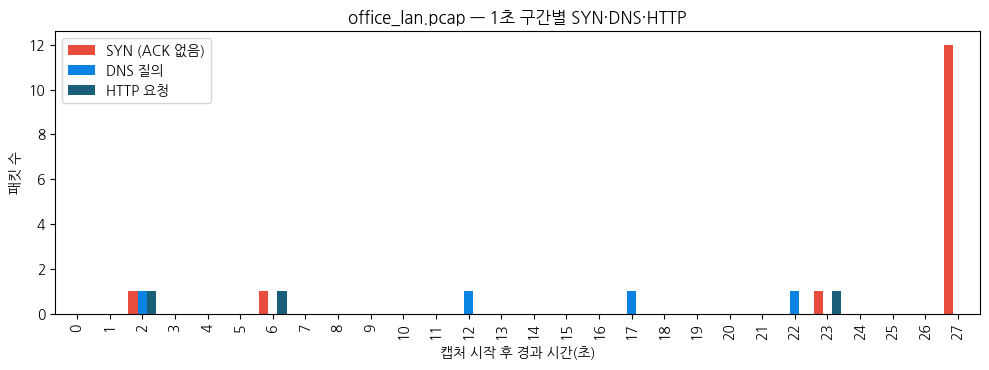

In [37]:
import matplotlib.pyplot as plt

# 세 종류 패킷의 시각을 뽑아 1초 구간으로 센 뒤 막대그래프로 그린다.
series = {
    "SYN (ACK 없음)": "tcp.flags.syn == 1 && tcp.flags.ack == 0",
    "DNS 질의": "dns.flags.response == 0",
    "HTTP 요청": "http.request",
}
counts = {}
for label, flt in series.items():
    t = tshark_fields("office_lan.pcap", flt, ["frame.time_relative"])["frame.time_relative"]
    counts[label] = t.astype(int).value_counts()
io_df = pd.DataFrame(counts).reindex(range(0, 28), fill_value=0).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(10, 3.8))
io_df.plot(kind="bar", ax=ax, width=0.85, color=["#e74c3c", "#0984e3", "#1a5f7a"])
ax.set_xlabel("캡처 시작 후 경과 시간(초)")
ax.set_ylabel("패킷 수")
ax.set_title("office_lan.pcap — 1초 구간별 SYN·DNS·HTTP")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

---
## Step 12. Wireshark 로 직접 열어 확인하기

로컬 PC 에 Wireshark 가 있으면 `office_lan.pcap` 을 내려받아 연다. Colab 에서는 아래 셀로 파일을 내려받는다.

| 확인 항목 | 조작 | 기대 결과 |
|---|---|---|
| 패킷 수와 기간 | Statistics › Capture File Properties | 71개, 약 27.6초 |
| 필드 이름 찾기 | 12번 패킷 상세에서 `Host` 클릭 → 상태 바 | `http.host` |
| 필드로 필터 만들기 | `Host` 우클릭 › Apply as Filter › Selected | 2개가 남는다 |
| 평문 로그인 | 22번 패킷 › Analyze › Follow › TCP Stream | `id=kim.analyst&pw=Spring` 과 `302 Found` |
| 스캔 | Statistics › Conversations › TCP 탭 | 192.168.10.77:61234 의 대화 12개 |
| 비컨 도메인 | 표시 필터 `dns.qry.name.len > 30` | 29~34번 6개 |
| 경고 | Analyze › Expert Information | Connection reset (RST) 12 |

In [38]:
try:
    from google.colab import files   # Colab 에서만 동작한다
    files.download("office_lan.pcap")
except ImportError:
    print("로컬 환경: 이 노트북과 같은 폴더에 생긴 office_lan.pcap 을 Wireshark 로 연다.")

로컬 환경: 이 노트북과 같은 폴더에 생긴 office_lan.pcap 을 Wireshark 로 연다.


---
## 챌린지. 조사 결과 한 문단 쓰기

지금까지의 출력만 근거로, 이 캡처에서 확인한 사실을 **한 문단**으로 정리한다. 다음을 포함한다.

- 의심 행위 세 가지와 각각의 근거(명령·필드·숫자)
- 관련 호스트와 사용자
- 추가로 확인해야 할 것(이 캡처만으로는 단정할 수 없는 것)

> 예시 답:
> *"2026-03-12 09:14:02~29(UTC) 캡처에서 세 가지를 확인했다. (1) 192.168.10.77 이 출발지 포트 61234 로 192.168.10.5 의 12개 포트에 0.012초 안에 SYN 을 보냈고 22·80·443 이 열린 것으로 응답했다(`tcp[tcpflags] == tcp-syn`, `-z conv,tcp`). (2) 192.168.10.23 에서 `www.example.com` 에 평문 HTTP 로 로그인했고 계정 `kim.analyst` 의 비밀번호가 노출됐으며 서버는 302 로 로그인을 허용했다(스트림 1). (3) 같은 PC 가 `cdn-update-check.net` 하위의 16자 무작위 이름을 5초 간격 TXT 로 조회한 뒤, `curl/8.5.0` 으로 PC 이름과 사용자 ID 를 203.0.113.66 에 POST 했다(스트림 2). 192.168.10.23 의 프로세스·EDR 기록으로 비컨 주체를 확인하고, 192.168.10.77 의 스캔이 승인된 점검인지 확인해야 한다."*

---
## 정리

- tcpdump: `-n`·`-c`·`-e`·`-v`·`-X`·`-A` 로 출력을 조절하고, BPF 필터로 좁히고, `-w`/`-r` 로 저장·재읽기를 한다.
- 캡처 필터(BPF)는 바이트·포트 기준, 표시 필터는 해석된 필드 기준이다. 포트로 거른 결과에는 스캔 패킷도 섞인다.
- Wireshark 세 영역은 tshark 기본 출력·`-V`/`-O`·`-x` 에 대응하고, Follow Stream·통계 메뉴는 `-z follow`·`-z conv`·`-z io,stat`·`-z expert` 에 대응한다.
- `-T fields` 결과를 pandas 로 받으면 "서로 다른 목적지 포트 수", "질의 이름 길이·간격" 같은 탐지 feature 가 된다.

다음 챕터(ch03)에서는 이 장에서 읽은 헤더 필드를 OSI·TCP/IP 계층으로 정리하고, Scapy 로 패킷을 직접 만들어 본다.